In [13]:

from pathlib import Path

import pandas as pd



project_root = Path.cwd()

print("Current directory:", project_root)


Databse_path = "../../../data/processed/emails.csv"



dataframe = pd.read_csv(Databse_path)

dataframe.head()


Current directory: /Users/mohamed/Documents/IT/student_prediction/AI projects/Spam Email Classifier/src/spam_filter/data


,id,filename,subject,body,label
0,0,00001.7c53336b37003a9286aba55d2945844c,Re: New Sequences Window,"Date: Wed, 21 Aug 2002 10:54:46 -0500\n...",ham
1,1,00002.9c4069e25e1ef370c078db7ee85ff9ac,[zzzzteana] RE: Alexander,"Martin A posted:\nTassos Papadopoulos, the Gre...",ham
2,2,00003.860e3c3cee1b42ead714c5c874fe25f7,[zzzzteana] Moscow bomber,Man Threatens Explosion In Moscow \n\nThursday...,ham
3,3,00004.864220c5b6930b209cc287c361c99af1,[IRR] Klez: The Virus That Won't Die,Klez: The Virus That Won't Die\n \nAlready the...,ham
4,4,00005.bf27cdeaf0b8c4647ecd61b1d09da613,Re: [zzzzteana] Nothing like mama used to make,"> in adding cream to spaghetti carbonara, whi...",ham


In [14]:


print("shape", dataframe.shape)


print()
print("Columns:")


print(dataframe.columns.tolist())

print()
print("Class distribution:")


print(dataframe.value_counts())
print(dataframe.value_counts(normalize=True))

print()
print("Missing values")



# isna() return DataFrame of bools 
print(dataframe.isna().sum())


dataframe["subject_length"] = dataframe["subject"].fillna("").str.len()

dataframe["body_length"] = dataframe["body"].fillna("").str.len()


print()
print("Text length statistics:")

print(dataframe[["subject_length", "body_length"]].describe())


print()
print("duplicated rows")


print(dataframe.duplicated(subset=["body" , "subject"]).sum())    



shape (2998, 5)

Columns:
['id', 'filename', 'subject', 'body', 'label']

Class distribution:
id    filename                                subject                                         body                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

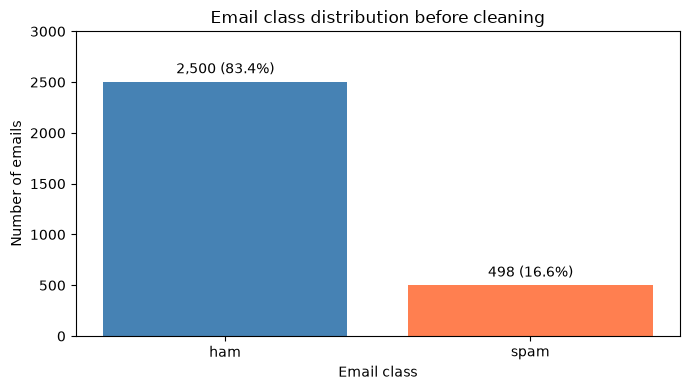

In [15]:
# import matplotlib.pyplot as plt

# dataframe["label"].value_counts().plot(
#     kind="bar",
#     title="Email Class Distribution",
#     xlabel="Label",
#     ylabel="Number of Emails",
# )

# plt.show()

import matplotlib.pyplot as plt

# 1. Normalize the labels and count emails in each class.
labels = dataframe["label"].str.lower().str.strip()

counts = labels.value_counts().reindex(
    ["ham", "spam"],
    fill_value=0,
)

percentages = counts / counts.sum() * 100

# 2. Create the figure and its plotting area.
fig, ax = plt.subplots(figsize=(7, 4))

# 3. Draw one bar per class.
bars = ax.bar(
    counts.index,
    counts.values,
    color=["steelblue", "coral"],
)

# 4. Write the count and percentage above each bar.
bar_labels = [
    f"{count:,} ({percentage:.1f}%)"
    for count, percentage in zip(counts, percentages)
]

ax.bar_label(bars, labels=bar_labels, padding=4)

# 5. Make the graph understandable without reading the code.
ax.set_title("Email class distribution before cleaning")
ax.set_xlabel("Email class")
ax.set_ylabel("Number of emails")
ax.set_ylim(0, counts.max() * 1.2)

fig.tight_layout()

fig.savefig(
    "class_distribution_before_cleaning.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()



In [16]:
print(dataframe["label"].value_counts())

label
ham     2500
spam     498
Name: count, dtype: int64


In [17]:
dataframe.groupby(["subject", "body"])

# .nunique().gt(1).sum()

In [18]:

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

emails = {
    "A": "Bonjour Aymane",
    "B": "Bonjour tous",
    "C": "Bonjour madame madame",
}

vectorizer = TfidfVectorizer()

# Learn the vocabulary and convert emails into vectors
vectors = vectorizer.fit_transform(emails.values())

# Display one row per email and one column per word
df = pd.DataFrame(
    vectors.toarray(),
    index=emails.keys(),
    columns=vectorizer.get_feature_names_out(),
)

print(df.round(3))

   aymane  bonjour  madame   tous
A   0.861    0.509   0.000  0.000
B   0.000    0.509   0.000  0.861
C   0.000    0.283   0.959  0.000


In [19]:
dataframe.head()

,id,filename,subject,body,label,subject_length,body_length
0,0,00001.7c53336b37003a9286aba55d2945844c,Re: New Sequences Window,"Date: Wed, 21 Aug 2002 10:54:46 -0500\n...",ham,24,1598
1,1,00002.9c4069e25e1ef370c078db7ee85ff9ac,[zzzzteana] RE: Alexander,"Martin A posted:\nTassos Papadopoulos, the Gre...",ham,25,894
2,2,00003.860e3c3cee1b42ead714c5c874fe25f7,[zzzzteana] Moscow bomber,Man Threatens Explosion In Moscow \n\nThursday...,ham,25,1746
3,3,00004.864220c5b6930b209cc287c361c99af1,[IRR] Klez: The Virus That Won't Die,Klez: The Virus That Won't Die\n \nAlready the...,ham,37,1125
4,4,00005.bf27cdeaf0b8c4647ecd61b1d09da613,Re: [zzzzteana] Nothing like mama used to make,"> in adding cream to spaghetti carbonara, whi...",ham,46,1047


In [20]:
import string


text = "Mohamed aassou !!"

ponctuations = str.maketrans("", "", string.punctuation)

text = text.translate(ponctuations)
text 


'Mohamed aassou '

In [21]:
vectorizer = TfidfVectorizer(stop_words="english" ,  lowercase=True)


vectorizer.stop_words

'english'

In [22]:


from sklearn.feature_extraction.text import TfidfVectorizer


vectorizer = TfidfVectorizer()

emails = {
    "A" : "Bonjour aymane",
    "B" : "Bonjour tous",
    "C" : "Bonjour monsieur monsieur",
}
vectors = vectorizer.fit_transform(emails.values())


df = pd.DataFrame(
    vectors.toarray(),
    index=emails.keys(),
    columns=vectorizer.get_feature_names_out(),
)



print(df.round(3))

vectorizer.get_feature_names_out()

   aymane  bonjour  monsieur   tous
A   0.861    0.509     0.000  0.000
B   0.000    0.509     0.000  0.861
C   0.000    0.283     0.959  0.000


array(['aymane', 'bonjour', 'monsieur', 'tous'], dtype=object)